# South Farm harvest analysis

In [1]:
from pathlib import Path
import os
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "05_south_farm":
    ROOT = ROOT.parent.parent
if not (ROOT / "batches").is_dir():
    raise FileNotFoundError("Open this notebook from the project folder.")
BATCH_DIR = ROOT / "batches/05_south_farm"
os.chdir(BATCH_DIR)
%matplotlib inline

## Dated harvests

Four dated harvests. Weights in grams.

In [2]:
from __future__ import annotations

import re

from pathlib import Path

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

HERE = BATCH_DIR

PROJECT = HERE.parents[1]

WORKBOOK = PROJECT / "data/processed/Harvest 2026 Sapkota lab CLEANED.xlsx"

FIGURES = HERE / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

HARVEST_SHEETS = {
    "SF_01_First_2026-07-23": "First",
    "SF_02_Second_2026-08-07": "Second",
    "SF_03_Third_2026-08-18_Nam": "Third",
    "SF_03_Third_2026-08-18_Ella": "Third",
    "SF_04_Fourth_2026-08-19_Nam": "Fourth",
}

def clean_genotype(value):
    if pd.isna(value):
        return value
    text = str(value).strip()
    match = re.match(r"(?i)^(?:uky[t]?\s*-?\s*)?(\d{2})\s*-?\s*(\d{1,3})$", text)
    if match:
        return f"UKYT-{match.group(1)}-{int(match.group(2)):03d}"
    return text

if not WORKBOOK.exists():
    raise FileNotFoundError(f"Cleaned workbook not found: {WORKBOOK}")

frames = []

for sheet, harvest_name in HARVEST_SHEETS.items():
    data = pd.read_excel(WORKBOOK, sheet_name=sheet).dropna(how="all").copy()
    data.columns = data.columns.map(lambda value: str(value).strip())
    data = data.loc[data["Genotypes"].notna()].copy()
    data["Source Sheet"] = sheet
    data["Harvest"] = data["Harvest"].fillna(harvest_name)
    frames.append(data)

master = pd.concat(frames, ignore_index=True)

master["Genotype_raw"] = master.get("Genotype_raw", master["Genotypes"])

master["Genotypes"] = master["Genotypes"].map(clean_genotype)

master["Date of harvest"] = pd.to_datetime(master["Date of harvest"], errors="coerce")

numeric_columns = [
    "Grade 1 Marketable (weight)",
    "Grade 1 Marketable (counts)",
    "Unmarketables (weight)",
    "Unmarketables (counts)",
    "Total Weight (g)",
    "Weight of 20 marketable (g)",
    "Weight of 20 fruit (g)",
]

for column in numeric_columns:
    if column not in master:
        master[column] = pd.NA
    master[column] = pd.to_numeric(master[column], errors="coerce")

## Measured weights

Grade 1 + unmarketable weight is used when both are recorded; otherwise the recorded total is used.

In [3]:
g1 = master["Grade 1 Marketable (weight)"]

unmarketable = master["Unmarketables (weight)"]

recorded_total = master["Total Weight (g)"]

both_components = g1.notna() & unmarketable.notna()

master["Computed Component Weight (g)"] = (g1 + unmarketable).where(both_components)

master["Total Harvest Weight (g)"] = master["Computed Component Weight (g)"].where(
    master["Computed Component Weight (g)"].notna(), recorded_total
)

master["Total Weight Source"] = pd.NA

master.loc[master["Computed Component Weight (g)"].notna(), "Total Weight Source"] = (
    "Grade 1 + unmarketable"
)

master.loc[
    master["Computed Component Weight (g)"].isna() & recorded_total.notna(),
    "Total Weight Source",
] = "recorded total"

master["Marketable Weight (g)"] = g1

master["Marketable Percentage"] = (
    master["Marketable Weight (g)"] / master["Total Harvest Weight (g)"] * 100
)

master["Weight of 20 fruit (g)"] = master["Weight of 20 fruit (g)"].combine_first(
    master["Weight of 20 marketable (g)"]
)

master["Mean Fruit Weight From 20 (g)"] = master["Weight of 20 fruit (g)"] / 20

## Entry metadata

In [4]:
metadata = pd.read_excel(WORKBOOK, sheet_name="SF_Entry_Metadata")

metadata.columns = metadata.columns.map(lambda value: str(value).strip())

metadata["Genotypes"] = metadata["Genotypes"].map(clean_genotype)

metadata = metadata.drop_duplicates("Genotypes").set_index("Genotypes")

master["Genotypes"] = master["Genotypes"].astype("string")

metadata["Genotypes"] = metadata.index.astype("string")

metadata_columns = [
    column
    for column in ["EN", "Experiment", "Source / pedigree", "Note", "Plants per entry", "Designed reps"]
    if column in metadata.columns
]

metadata_lookup = metadata[metadata_columns].reset_index(drop=True)

metadata_lookup.insert(0, "Genotypes", metadata.index)

master = master.merge(metadata_lookup, on="Genotypes", how="left", suffixes=("", "_metadata"))

if "Experiment_metadata" in master.columns:
    master["Experiment"] = master["Experiment"].combine_first(master["Experiment_metadata"])
    master = master.drop(columns="Experiment_metadata")

master_path = HERE / "south_farm_harvest_master.csv"

master.to_csv(master_path, index=False)

## Genotype and harvest summaries

In [5]:
by_harvest = master.groupby(["Genotypes", "Harvest"], dropna=False).agg(
    n_plot_rows=("Genotypes", "size"),
    harvest_weight_g=("Total Harvest Weight (g)", lambda values: values.sum(min_count=1)),
    marketable_weight_g=("Marketable Weight (g)", lambda values: values.sum(min_count=1)),
    unmarketable_weight_g=("Unmarketables (weight)", lambda values: values.sum(min_count=1)),
).reset_index()

harvest_order = ["First", "Second", "Third", "Fourth"]

by_harvest["Harvest"] = pd.Categorical(by_harvest["Harvest"], categories=harvest_order, ordered=True)

summary = by_harvest.groupby("Genotypes", dropna=False).agg(
    n_harvests_with_weight=("harvest_weight_g", "count"),
    total_weight_g=("harvest_weight_g", lambda values: values.sum(min_count=1)),
    total_marketable_weight_g=("marketable_weight_g", lambda values: values.sum(min_count=1)),
    total_unmarketable_weight_g=("unmarketable_weight_g", lambda values: values.sum(min_count=1)),
    mean_weight_per_harvest_g=("harvest_weight_g", "mean"),
).reset_index()

summary["marketable_percentage"] = (
    summary["total_marketable_weight_g"] / summary["total_weight_g"] * 100
)

fruit_size = master.groupby("Genotypes")["Mean Fruit Weight From 20 (g)"].mean()

summary["mean_fruit_weight_from_20_g"] = summary["Genotypes"].map(fruit_size)

summary = summary.merge(metadata_lookup, on="Genotypes", how="left")

brix_path = PROJECT / "batches/03_brix/genotype_location_brix.csv"

if brix_path.exists():
    brix = pd.read_csv(brix_path)
    sf_brix = brix.loc[
        brix["Location"].astype("string").str.strip().eq("South Farm"),
        ["Genotypes", "n", "mean_brix"],
    ].rename(columns={"n": "n_brix", "mean_brix": "mean_brix_south_farm"})
    sf_brix["Genotypes"] = sf_brix["Genotypes"].map(clean_genotype)
    summary = summary.merge(sf_brix, on="Genotypes", how="left")
else:
    summary["n_brix"] = pd.NA
    summary["mean_brix_south_farm"] = pd.NA

summary = summary.sort_values(
    ["total_weight_g", "Genotypes"], ascending=[False, True], na_position="last"
).reset_index(drop=True)

summary["rank_total_weight"] = range(1, len(summary) + 1)

summary["rank_mean_per_harvest"] = pd.NA

eligible_mean = summary.loc[summary["n_harvests_with_weight"] >= 3].sort_values(
    ["mean_weight_per_harvest_g", "Genotypes"], ascending=[False, True]
).copy()

eligible_mean["rank_mean_per_harvest"] = range(1, len(eligible_mean) + 1)

summary["rank_mean_per_harvest"] = summary["Genotypes"].map(
    eligible_mean.set_index("Genotypes")["rank_mean_per_harvest"]
)

summary.to_csv(HERE / "south_farm_genotype_summary.csv", index=False)

top_total = summary.dropna(subset=["total_weight_g"]).head(15).copy()

top_total.to_csv(HERE / "south_farm_top15_total_weight.csv", index=False)

top_mean = eligible_mean.head(15).copy()

top_mean.to_csv(HERE / "south_farm_top15_mean_per_harvest_ge3.csv", index=False)

## Hybrid evaluation

The undated hybrid block is excluded from season totals.

In [6]:
hybrid = pd.read_excel(WORKBOOK, sheet_name="SF_Hybrid").dropna(how="all").copy()

hybrid.columns = hybrid.columns.map(lambda value: str(value).strip())

hybrid = hybrid.loc[hybrid["Genotypes"].notna()].copy()

hybrid["Genotype_raw"] = hybrid.get("Genotype_raw", hybrid["Genotypes"])

hybrid["Genotypes"] = hybrid["Genotypes"].map(clean_genotype)

for column in ["Grade 1 Marketable (weight)", "Unmarketables (weight)", "Total Weight (g)"]:
    if column not in hybrid:
        hybrid[column] = pd.NA
    hybrid[column] = pd.to_numeric(hybrid[column], errors="coerce")

hybrid_components = hybrid["Grade 1 Marketable (weight)"] + hybrid["Unmarketables (weight)"]

hybrid_both = hybrid["Grade 1 Marketable (weight)"].notna() & hybrid["Unmarketables (weight)"].notna()

hybrid["Total Harvest Weight (g)"] = hybrid_components.where(hybrid_both, hybrid["Total Weight (g)"])

hybrid["Marketable Percentage"] = hybrid["Grade 1 Marketable (weight)"] / hybrid["Total Harvest Weight (g)"] * 100

hybrid = hybrid.sort_values("Total Harvest Weight (g)", ascending=False, na_position="last")

hybrid.to_csv(HERE / "south_farm_hybrid_evaluation.csv", index=False)

## Yield plots

In [7]:
source_counts = master["Total Weight Source"].value_counts(dropna=False)

top = top_total.iloc[0]

best_mean = top_mean.iloc[0] if not top_mean.empty else None

n_brix = int(summary["mean_brix_south_farm"].notna().sum())

plot_df = top_total.sort_values("total_weight_g", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6.8))

ax.barh(plot_df["Genotypes"], plot_df["total_weight_g"] / 1000, color="#0033A0")

ax.set_xlabel("Cumulative recorded harvest weight (kg)")

ax.set_title("South Farm: top 15 by cumulative harvest weight")

ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

fig.savefig(FIGURES / "sf_top15_total_weight.png", dpi=160)

plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 5.5))

plot_mean = top_mean.sort_values("mean_weight_per_harvest_g", ascending=True)

ax.barh(plot_mean["Genotypes"], plot_mean["mean_weight_per_harvest_g"] / 1000, color="#5B8DEF")

ax.set_xlabel("Mean weight per harvest with recorded weight (kg)")

ax.set_title("South Farm: top entries with weight in at least three harvests")

ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

fig.savefig(FIGURES / "sf_top_mean_per_harvest_ge3.png", dpi=160)

plt.close(fig)

fig, ax = plt.subplots(figsize=(7.8, 5.4))

brix_overlap = summary.dropna(subset=["total_weight_g", "mean_brix_south_farm"])

if not brix_overlap.empty:
    ax.scatter(
        brix_overlap["mean_brix_south_farm"], brix_overlap["total_weight_g"] / 1000,
        c="#0033A0", alpha=0.78, edgecolors="white", linewidths=0.4,
    )
    for _, row in brix_overlap.nlargest(5, "total_weight_g").iterrows():
        ax.annotate(row["Genotypes"], (row["mean_brix_south_farm"], row["total_weight_g"] / 1000),
                    xytext=(4, 4), textcoords="offset points", fontsize=7)
    ax.set_xlabel("Mean South Farm °Brix")
    ax.set_ylabel("Cumulative harvest weight (kg)")
    ax.set_title("South Farm yield and °Brix overlap")
else:
    ax.text(0.5, 0.5, "No paired yield and °Brix observations", ha="center", va="center")
    ax.set_axis_off()

fig.tight_layout()

fig.savefig(FIGURES / "sf_yield_vs_brix.png", dpi=160)

plt.close(fig)

## Summary table

In [8]:
review = pd.read_csv("south_farm_genotype_summary.csv")
display(review[['Genotypes', 'n_harvests_with_weight', 'total_weight_g', 'mean_weight_per_harvest_g', 'marketable_percentage']].head(10))
print("Exported rows:", len(review))

,Genotypes,n_harvests_with_weight,total_weight_g,mean_weight_per_harvest_g,marketable_percentage
0,Mt. Girl,2,31992.0,15996.000000,54.648037
1,NC25306G,2,31712.0,15856.000000,60.910696
2,UKYT-26-036,3,26714.0,8904.666667,13.071798
3,Mt. Magic,2,25053.0,12526.500000,84.109687
4,NC264G,2,24736.0,12368.000000,67.686772
5,UKYT-26-026,3,24318.0,8106.000000,24.348219
6,NC25212G,2,22345.0,11172.500000,58.621616
7,Mountain Fresh,2,21885.0,10942.500000,NaN
8,UKYT-26-003,2,21540.0,10770.000000,14.173630
9,NC25230G,2,20605.0,10302.500000,66.915797


Exported rows: 108


## Figures

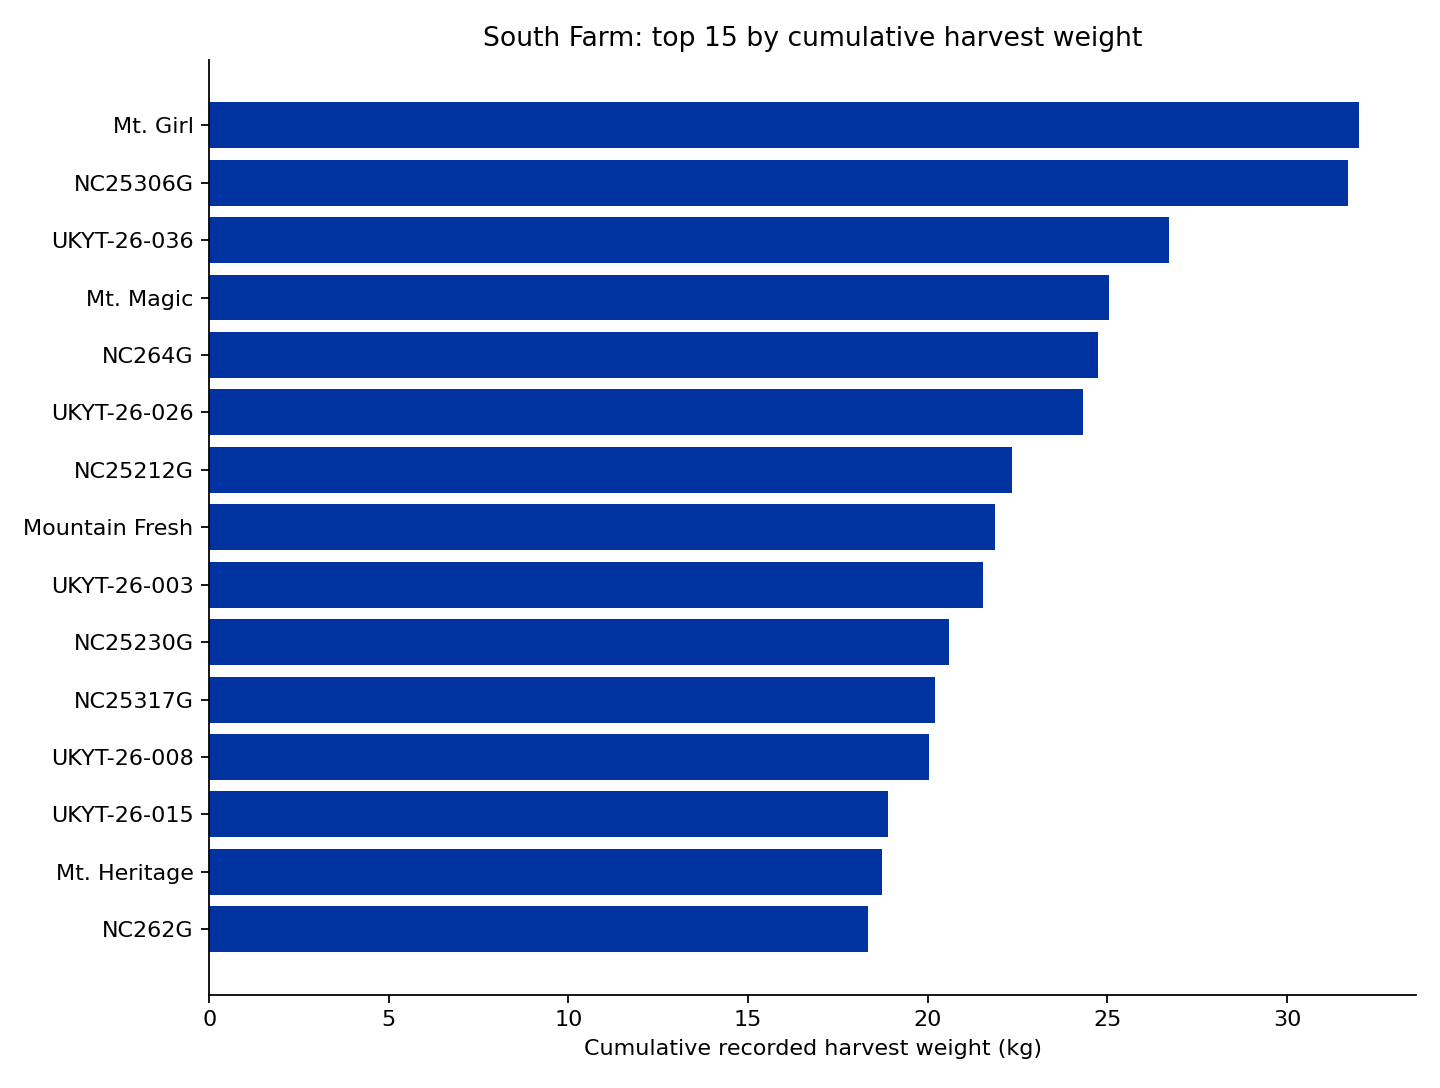

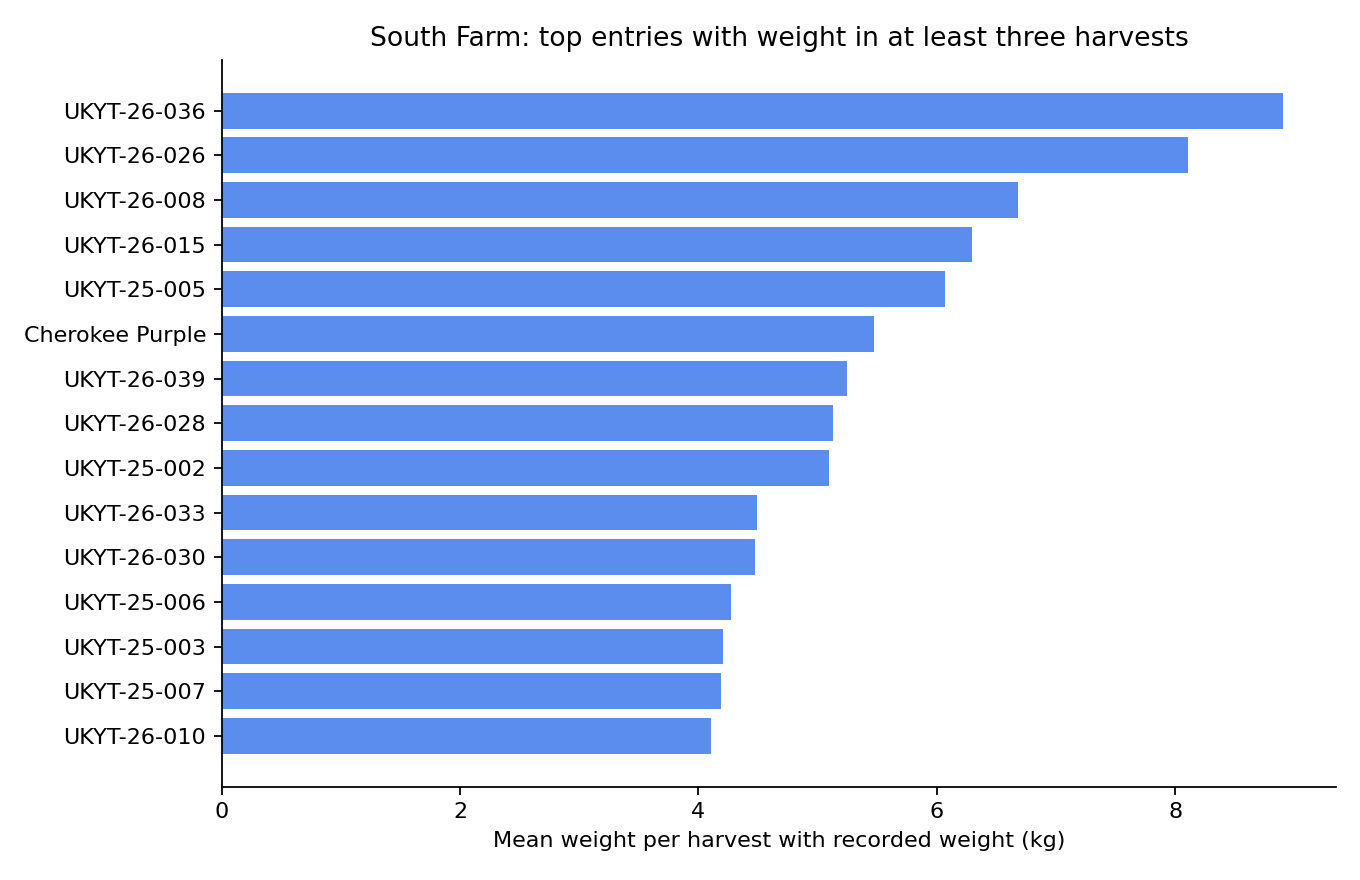

In [9]:
display(Image(filename="figures/sf_top15_total_weight.png"))
display(Image(filename="figures/sf_top_mean_per_harvest_ge3.png"))